# Supplementary Figure S8c. Enrichment of *cis*-only, *cis*-*trans* and *trans*-only variants in highly conserved sequence

Enrichment of all credible-set variants of *cis*-only, *cis*-*trans* and *trans*-only colocalized loci in sequence with Zoonomia primate PhastCons > 0.9, against all ROSMAP MAF ≥ 5% variants (7,563,438) as background, shown separately for *trans*-eGene (top) and *trans*-eProgram (bottom); loci are the main-Figure-3a filtered set (*trans* loci only if they also colocalize with a biomarker-QTL), as in the published figure. Enrichment is the conditional-MLE odds ratio from a one-sided (greater) Fisher's exact test. Error bars are 95% Woolf CIs, exp(log OR ± 1.96 × SE), with SE = sqrt(1/a+1/b+1/c+1/d) (cells floored at 0.5); they are not leave-one-chromosome-out jackknife intervals. Asterisks mark BH FDR < 5%, with BH applied across 6 tests per *trans* method (3 groups × 2 conservation sets, the second being Zoonomia mammal PhyloP, not shown).

Input: `data/Figure_S8c_phastcons_enrichment.rds`.

In [1]:
library(ggplot2)
s8c <- readRDS("data/Figure_S8c_phastcons_enrichment.rds")
s8c

trans_method,category,conservation_set,n_query_variants,n_overlap,n_conserved_background,n_background_variants,odds_ratio,se_log_or,ci_low,ci_high,p_value,p_adj,significant_fdr05
<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
trans-eGene,cis-only,Zoonomia Primate PhastCons > 0.9,172604,5769,150758,7563438,1.7280901,0.013651714,1.6824641,1.7749534,1.363049e-301,8.178291e-301,TRUE
trans-eGene,cis-trans,Zoonomia Primate PhastCons > 0.9,220152,6004,150758,7563438,1.3942307,0.013351872,1.3582174,1.4311989,8.552919e-125,2.565876e-124,TRUE
trans-eGene,trans-only,Zoonomia Primate PhastCons > 0.9,676714,13049,150758,7563438,0.9636200,0.009249371,0.9463081,0.9812485,9.999721e-01,9.999721e-01,FALSE
trans-eProgram,cis-only,Zoonomia Primate PhastCons > 0.9,172604,5769,150758,7563438,1.7280901,0.013651714,1.6824641,1.7749534,1.363049e-301,8.178291e-301,TRUE
trans-eProgram,cis-trans,Zoonomia Primate PhastCons > 0.9,190047,5160,150758,7563438,1.3854413,0.014360144,1.3469905,1.4249898,2.876969e-104,5.753938e-104,TRUE
trans-eProgram,trans-only,Zoonomia Primate PhastCons > 0.9,531726,10267,150758,7563438,0.9657635,0.010323766,0.9464181,0.9855044,9.996561e-01,9.996561e-01,FALSE


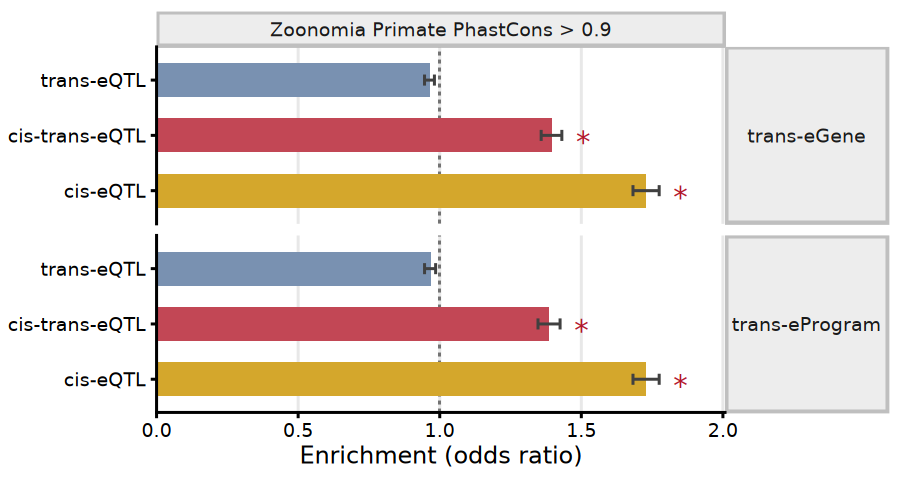

In [2]:
cols   <- c("cis-only" = "#D4A72C", "cis-trans" = "#C24755", "trans-only" = "#7991B1")
labels <- c("cis-only" = "cis-eQTL", "cis-trans" = "cis-trans-eQTL", "trans-only" = "trans-eQTL")
s8c$category <- factor(s8c$category, levels = names(cols))
s8c$star <- ifelse(s8c$significant_fdr05, "*", "")

p <- ggplot(s8c, aes(y = category, x = odds_ratio, fill = category)) +
  geom_vline(xintercept = 1, linetype = "dashed", color = "grey45") +
  geom_col(width = 0.6, orientation = "y") +
  geom_errorbar(aes(xmin = ci_low, xmax = ci_high), width = 0.2, orientation = "y", color = "grey25") +
  geom_text(aes(x = ci_high + 0.05, label = star), color = "#B2182B", size = 6, hjust = 0, vjust = 0.75) +
  facet_grid(rows = vars(trans_method), cols = vars(conservation_set)) +
  scale_y_discrete(labels = labels) +
  scale_fill_manual(values = cols, guide = "none") +
  scale_x_continuous(expand = expansion(mult = c(0, 0.1))) +
  labs(x = "Enrichment (odds ratio)", y = NULL) +
  theme_classic(base_size = 14) +
  theme(strip.background = element_rect(fill = "grey93", color = "grey75"),
        strip.text.y = element_text(angle = 0),
        panel.grid.major.x = element_line(color = "grey91"))

options(repr.plot.width = 7.5, repr.plot.height = 4)
p